# 02 - Power curve of WTG 01

In this notebook we estimate the power curve $P(v)$ of the turbine, meaning how much power it produces at a given wind speed.
We need this curve in all later notebooks to turn a (simulated) wind speed forecast into a power forecast.

Before implementing the chosen method we first clean the data and additionally do a random split of the cleaned data and use 80% as the training set and reserve 20% as a calibration set to be used later for our conformal prediction ( Notebook4). Until then, all steps are conducted on the 80% training set only. 

**Method:** we use a standardized method by the IEC (International Electrotechnical Comission) (Standard: IEC 61400-12-1) which splits the data into bins (in our case 0.5 m/s bins, mean $v$ and mean $P$ per bin) calculates the mean for each bin and connects the bin means with a function. The industry standard uses straight lines to connect the means. In our case we chose to use a PCHIP
(monotone piecewise cubic interpolation) function, as it results in a smooth curve which means we can later take its derivative to show how its slope $P'(v)$ relates the wind speed error to the power error (notebook 03).



Steps:
1. Load data
2. Cleaning
3. Split the cleaned hours into 80 % training and 20 % calibration hours
4. Power curve: bins + PCHIP
5. Validation: leave-one-month-out
6. Save the curve and the hours for the next notebooks

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy.interpolate import PchipInterpolator
import openpyxl

FILE = "Wind_Data_WTG_01_20250101.xlsx"
BIN_WIDTH = 0.5           # m/s, as in IEC 61400-12-1
MIN_COUNT = 5             # bins with fewer hours are too noisy and are dropped
CALIBRATION_SHARE = 0.2   # share of the cleaned hours we keep for the conformal prediction (notebook 04)
SEED = 42                 # fixed seed so that we all get the same split

# colors of the slide deck (taken from the title photo of the presentation)
DEEP = "#3d5687"        # deep sky: bin means, emphasis
BLUE = "#5b86bd"        # sky: wind
LIGHT_BLUE = "#9dbbe0"  # light sky: data points behind a curve
TEAL = "#6fa9b6"        # horizon teal: second series
ORANGE = "#e8673a"      # blade tip: power
GRAY = "#b9c3cd"        # light haze: context
DARK_GRAY = "#6e7f8f"   # dark haze: axes and context points
INK = "#24324a"         # text and lines

# the plots that are on the slides are saved here, at the size they have on the slide
FIGURE_DIR = "Presentation/figures"

# font of the slides: Aptos comes with PowerPoint, without PowerPoint we use Arial
APTOS_DIR = Path("/Applications/Microsoft PowerPoint.app/Contents/Resources/DFonts")
for font_file in APTOS_DIR.glob("Aptos*.ttf"):
    font_manager.fontManager.addfont(str(font_file))
if (APTOS_DIR / "Aptos.ttf").exists():
    FONT = "Aptos"
else:
    FONT = "Arial"

plt.rcParams.update({
    "font.family": FONT,
    "font.size": 10,
    "axes.labelsize": 10.5,
    "axes.labelcolor": INK,
    "axes.edgecolor": DARK_GRAY,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6eaee",
    "grid.linewidth": 0.6,
    "xtick.color": DARK_GRAY,
    "ytick.color": DARK_GRAY,
    "xtick.labelcolor": INK,
    "ytick.labelcolor": INK,
    "legend.frameon": False,
    "figure.dpi": 150,    # shows the small slide figures a bit larger in the notebook
    "savefig.dpi": 220,   # resolution of the saved slide figures
    "mathtext.fontset": "custom",
    "mathtext.rm": FONT,
    "mathtext.it": FONT + ":italic",
    "mathtext.cal": FONT,   # we use no cursive math; the default cursive font of the Mac gives a font warning
})

# cleaning slide: one color and marker for each cleaning rule
RULE_STYLES = {
    1: {"color": TEAL, "marker": "D"},        # empty row / duplicated hour (DST)
    2: {"color": DEEP, "marker": "s"},        # maintenance stop / next to a data gap
    3: {"color": "#b08d3c", "marker": "^"},   # stopped but windy (darker ochre)
    4: {"color": ORANGE, "marker": "o"},      # outlier within its bin (1.5 IQR)
}

def style_power_axes(ax, xlabel="wind speed v [m/s]"):
    """Axes of the wind speed vs. power plots, the same on every slide.

    Args:
        ax: Matplotlib axes.
        xlabel: Label of the x axis.
    """
    ax.set_xlim(0, 17)
    ax.set_xticks([0, 5, 10, 15])
    ax.set_ylim(-60, 1150)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("power P [kW]")
    ax.grid(axis="x", visible=False)

## 1. Load data

We only need the hourly mean wind speed, the hourly mean power and the maintenance stop time.
`Gen. Out.Energy(kWh)` is not used because it has catch-up values after data gaps.
The maintenance time is stored as text like `"01:00:00"`, so we convert it to minutes.
As in notebook 00, wind speed $v$ is the column `v` and power $P$ is `p`.

In [2]:
# load the excel file and keep the columns we need
raw = pd.read_excel(FILE)
df = raw.rename(columns={"Time": "time",
                         "WindSpeedAve.(m/s)": "v",
                         "GeneratorOutput(kW)": "p",
                         "MaintenanceStop Time(min)": "maint"})
df = df[["time", "v", "p", "maint"]]

# maintenance stop time: text "hh:mm:ss" -> minutes
df["maint"] = pd.to_timedelta(df["maint"].astype(str), errors="coerce").dt.total_seconds() / 60
df["month"] = df["time"].dt.month
print(f"{len(df)} hours, {df['p'].isna().sum()} without data")
df.head()

8761 hours, 55 without data


,time,v,p,maint,month
0,2025-01-01 00:00:00,3.4,5.9,0.0,1
1,2025-01-01 01:00:00,3.5,5.4,0.0,1
2,2025-01-01 02:00:00,3.2,-1.2,0.0,1
3,2025-01-01 03:00:00,3.7,15.7,0.0,1
4,2025-01-01 04:00:00,3.4,5.1,0.0,1


## 2. Cleaning

We use simple rules that are easy to explain. Each hour is counted under the first rule that removes it.
1. empty rows, and the duplicated hour at the end of daylight saving time (26 Oct 03:00 exists twice),
2. hours with a maintenance stop, and the hour before and after each data gap (often stops that are not flagged),
3. "stopped but windy": $P \le 1$ kW at $v > 4$ m/s,
4. outliers within each 0.5 m/s bin: points outside $[Q_1 - 1.5\,\text{IQR},\; Q_3 + 1.5\,\text{IQR}]$.

The three plots show all hours before the cleaning, the removed hours colored by the rule that removed them
(1 teal diamonds, 2 dark blue squares, 3 ochre triangles, 4 orange dots) and the hours we keep.

In [3]:
# rules 1-3 as True/False masks (True = remove the hour)
gap = df["v"].isna() | df["p"].isna()
next_to_gap = (gap.shift(1, fill_value=False) | gap.shift(-1, fill_value=False)) & ~gap

rules = {
    "1. empty row": gap,
    "1. duplicated DST hour": df["time"].duplicated(keep=False),
    "2. maintenance stop": df["maint"] > 0,
    "2. hour next to a data gap": next_to_gap,
    "3. stopped but windy": (df["p"] <= 1) & (df["v"] > 4),
}

# apply the rules in order, an hour is only counted for the first rule that removes it
keep = pd.Series(True, index=df.index)
rule_number = pd.Series(0, index=df.index)   # number of the rule that removed the hour (0 = kept), for the cleaning slide
removed = {}
for rule, mask in rules.items():
    newly_removed = mask & keep
    removed[rule] = int(newly_removed.sum())
    rule_number[newly_removed] = int(rule[0])   # the first character of the rule name is its number
    keep = keep & ~mask
available = keep.copy()   # passed rules 1-3: data ok and turbine running

# rule 4: outliers within each wind speed bin (more than 1.5 IQR outside the quartiles)
bin_of_hour = (df["v"] / BIN_WIDTH).round() * BIN_WIDTH
p_kept = df["p"][keep]
bin_kept = bin_of_hour[keep]
q1 = p_kept.groupby(bin_kept).transform("quantile", 0.25)
q3 = p_kept.groupby(bin_kept).transform("quantile", 0.75)
iqr = q3 - q1
outlier = (p_kept < q1 - 1.5 * iqr) | (p_kept > q3 + 1.5 * iqr)
outlier = outlier.reindex(df.index, fill_value=False)   # back to all hours, False for hours removed before
removed["4. outlier within bin (1.5 IQR)"] = int(outlier.sum())
rule_number[outlier] = 4
keep = keep & ~outlier

clean = df[keep].copy()
removed["kept"] = len(clean)
pd.Series(removed, name="hours").to_frame()

,hours
1. empty row,55
1. duplicated DST hour,2
2. maintenance stop,80
2. hour next to a data gap,30
3. stopped but windy,52
4. outlier within bin (1.5 IQR),573
kept,7969


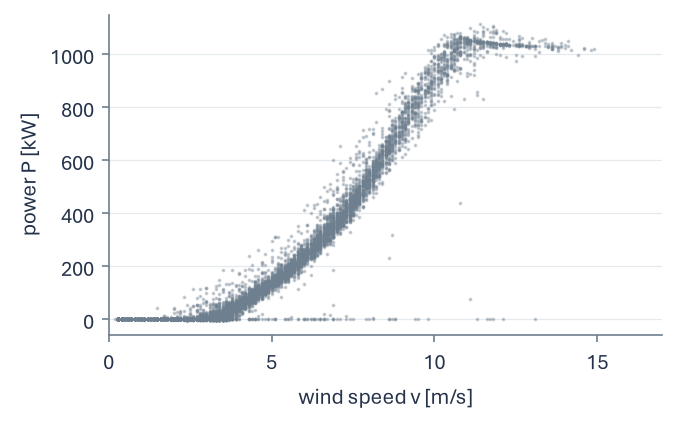

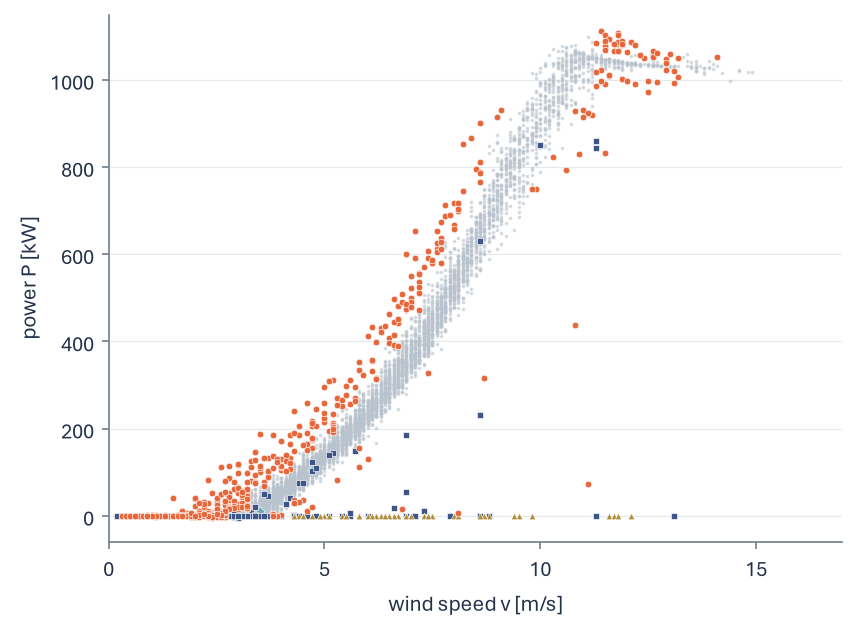

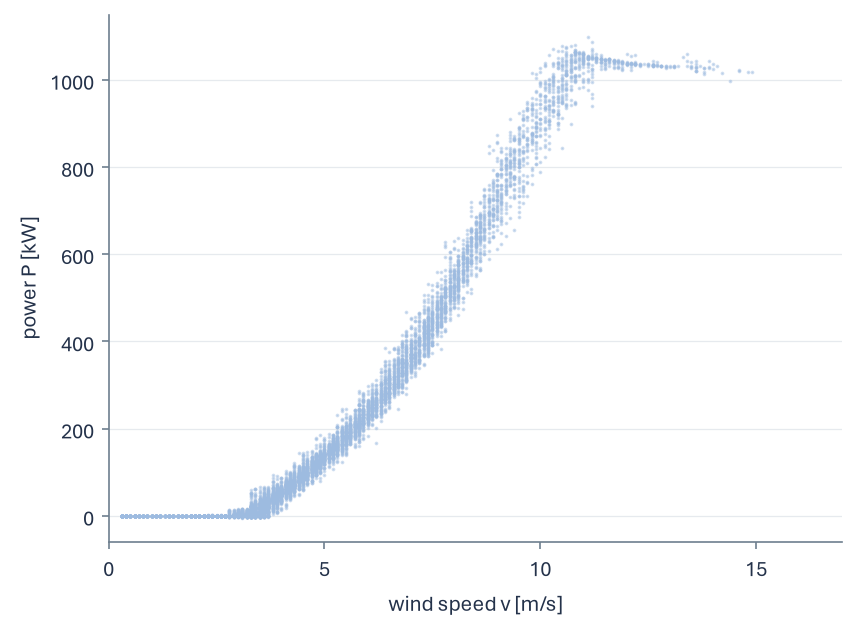

In [4]:
# all hours of the year before the cleaning (slide 8)
fig, ax = plt.subplots(figsize=(4.4, 2.72), layout="constrained")
ax.plot(df["v"], df["p"], ".", ms=1.6, color=DARK_GRAY, alpha=0.35, rasterized=True)
style_power_axes(ax)
fig.savefig(f"{FIGURE_DIR}/raw_scatter.png", transparent=False, facecolor="white")
plt.show()

# the same hours, the removed ones colored by the rule that removed them (slide 9, the legend is on the slide)
fig, ax = plt.subplots(figsize=(5.6, 4.1), layout="constrained")
ax.plot(df["v"][keep], df["p"][keep], ".", ms=1.6, color=GRAY, alpha=0.5, rasterized=True)
for number, style in RULE_STYLES.items():
    hit = (rule_number == number) & df["v"].notna() & df["p"].notna()
    ax.scatter(df["v"][hit], df["p"][hit], s=10, marker=style["marker"], color=style["color"],
               edgecolor="white", linewidth=0.3, zorder=3)
style_power_axes(ax)
fig.savefig(f"{FIGURE_DIR}/cleaning_rules.png", transparent=False, facecolor="white")
plt.show()

# the hours we keep (slide 10)
fig, ax = plt.subplots(figsize=(5.6, 4.1), layout="constrained")
ax.plot(clean["v"], clean["p"], ".", ms=1.6, color=LIGHT_BLUE, alpha=0.45, rasterized=True)
style_power_axes(ax)
fig.savefig(f"{FIGURE_DIR}/cleaned_scatter.png", transparent=False, facecolor="white")
plt.show()

## 3. Training and calibration hours

For the conformal prediction (notebook 04) we need hours that the curve is not trained on. Only on these hours the errors show honestly how
far off the curve can be. So before we fit anything we split the cleaned hours at random:
- **80 % training hours:** the power curve and its validation use only these hours,
- **20 % calibration hours:** notebook 03 adds noise to their wind speed and notebook 04 computes the conformal intervals from them.

We randomize the selection istead of doing a monthly split, to avoid seasonal bias.

In [5]:
# random 80/20 split of the cleaned hours (fixed seed)
rng = np.random.default_rng(SEED)
order = rng.permutation(len(clean))
n_calibration = int(round(CALIBRATION_SHARE * len(clean)))
calibration_index = clean.index[order[:n_calibration]]
clean["split"] = "train"
clean.loc[calibration_index, "split"] = "calibration"
train = clean[clean["split"] == "train"]
calibration = clean[clean["split"] == "calibration"]
print(f"{len(train)} training hours, {len(calibration)} calibration hours")

6375 training hours, 1594 calibration hours


## 4. Power curve: method of bins + PCHIP

**Method of bins:** we group the training hours into 0.5 m/s bins and take the mean $v$ and the mean $P$ of each bin.
We also keep the standard deviation of $P$ in each bin (the scatter of the measurements).

**PCHIP** (piecewise cubic Hermite interpolation) connects the bin means with cubic pieces. The curve goes exactly through every bin
mean, its first derivative is continuous and it does not overshoot: where the bin means rise, the curve rises too.
The second derivative jumps at the bin means, so we don't use $P''(v)$.

Outside the measured range we set $P = 0$ below the first bin and keep the power of the last bin above the last bin.
Above about 13 m/s there are only a few dozen hours, so this part of the curve is uncertain.

In [6]:
def bin_table(v, p):
    """Average wind speed and power per wind speed bin (IEC method of bins).

    Args:
        v: Hourly mean wind speeds in m/s.
        p: Hourly mean power in kW, same length as ``v``.

    Returns:
        DataFrame with one row per bin: mean ``v``, mean ``p``, standard deviation ``p_std``
        and number of hours ``n``. Bins with fewer than ``MIN_COUNT`` hours are dropped.
    """
    bin_centre = (v / BIN_WIDTH).round() * BIN_WIDTH
    table = pd.DataFrame({"v": v, "p": p}).groupby(bin_centre).agg(
        v=("v", "mean"), p=("p", "mean"), p_std=("p", "std"), n=("p", "size"))
    return table[table["n"] >= MIN_COUNT]


def power_curve(table, v):
    """Power from the PCHIP curve through the bin means.

    Below the first bin the power is 0, above the last bin it stays at the power of the last bin.

    Args:
        table: Bin table from ``bin_table`` with the bin means in the columns ``v`` and ``p``.
        v: Wind speeds in m/s.

    Returns:
        Array with the power in kW for each wind speed.
    """
    v = np.asarray(v, dtype=float)
    v_first = table["v"].iloc[0]
    v_last = table["v"].iloc[-1]
    pchip = PchipInterpolator(table["v"], table["p"])
    p = pchip(np.clip(v, v_first, v_last))
    p = np.where(v < v_first, 0.0, p)
    p = np.where(v > v_last, table["p"].iloc[-1], p)
    return p


def power_curve_slope(table, v):
    """Slope P'(v) of the PCHIP curve through the bin means (0 outside the bins).

    Args:
        table: Bin table from ``bin_table`` with the bin means in the columns ``v`` and ``p``.
        v: Wind speeds in m/s.

    Returns:
        Array with the slope in kW per m/s for each wind speed.
    """
    v = np.asarray(v, dtype=float)
    v_first = table["v"].iloc[0]
    v_last = table["v"].iloc[-1]
    slope = PchipInterpolator(table["v"], table["p"]).derivative()  # PchipInterpolator function from the scipy.interpolate module is used to create a piecewise cubic Hermite interpolating polynomial (PCHIP) based on the bin means of wind speed and power. 
                                                                    # The derivative() method is then called on this PCHIP object to obtain the slope of the curve, which represents the rate of change of power with respect to wind speed. 
    dp = slope(np.clip(v, v_first, v_last))
    dp = np.where((v < v_first) | (v > v_last), 0.0, dp)
    return dp


# bin table of the training hours
bins = bin_table(train["v"], train["p"])
bins.round(1)

,v,p,p_std,n
v,,,,
0.5,0.4,0.0,0.0,308
1.0,1.0,0.0,0.0,112
1.5,1.5,0.0,0.0,98
2.0,2.0,-0.2,0.3,154
2.5,2.5,-0.2,0.5,206
3.0,3.0,1.6,4.2,478
3.5,3.5,16.8,15.9,756
4.0,4.0,52.6,17.4,551
4.5,4.5,93.1,19.4,477


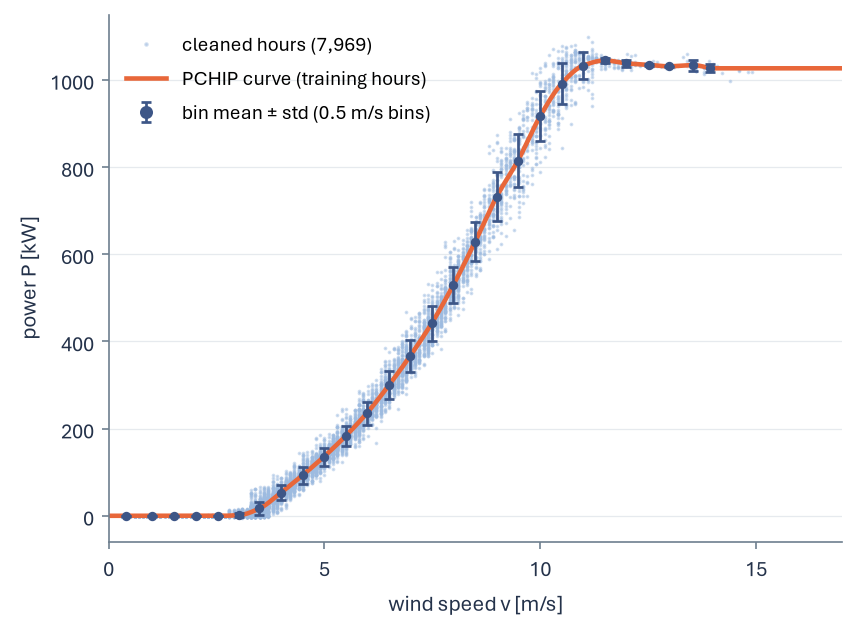

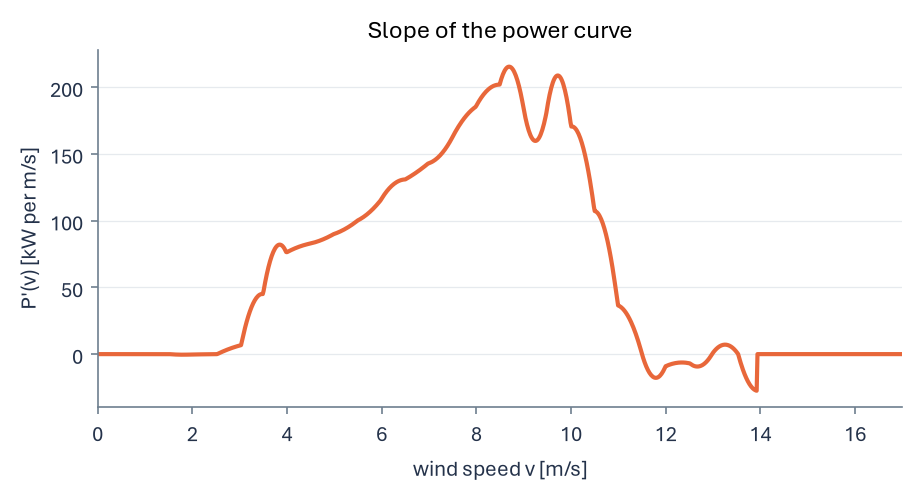

In [7]:
# the fitted curve over all cleaned hours, with the bin means +/- std of the training hours (slide 11)
v_grid = np.linspace(0, 17, 1000)
fig, ax = plt.subplots(figsize=(5.6, 4.1), layout="constrained")
ax.plot(clean["v"], clean["p"], ".", ms=1.6, color=LIGHT_BLUE, alpha=0.45, rasterized=True,
        label=f"cleaned hours ({len(clean):,})")
ax.plot(v_grid, power_curve(bins, v_grid), color=ORANGE, lw=2.2, label="PCHIP curve (training hours)")
# error bars in deep blue on top of the light points, so the spread per bin stays visible
ax.errorbar(bins["v"], bins["p"], yerr=bins["p_std"], fmt="o", ms=3.5, color=DEEP, ecolor=DEEP,
            elinewidth=1.3, capsize=2.5, capthick=1.3, zorder=4, label="bin mean ± std (0.5 m/s bins)")
ax.legend(loc="upper left", fontsize=9.5, markerscale=1.5)
style_power_axes(ax)
fig.savefig(f"{FIGURE_DIR}/power_curve_fit.png", transparent=False, facecolor="white")
plt.show()

# slope of the curve, we need it for the error propagation in notebook 03
fig, ax = plt.subplots(figsize=(6, 3.2), layout="constrained")
ax.plot(v_grid, power_curve_slope(bins, v_grid), color=ORANGE, lw=2)
ax.set(title="Slope of the power curve", xlabel="wind speed v [m/s]", ylabel="P'(v) [kW per m/s]", xlim=(0, 17))
ax.grid(axis="x", visible=False)
plt.show()

## 5. Validation: leave-one-month-out

We fit the curve on 11 months and predict the 12th, for every month. A random train/test split of the hours would be too optimistic,
because hours next to each other are very similar. We only use the training hours here, so the choice between PCHIP and
straight lines does not see the calibration hours.

Error measures on the left-out hours: RMSE, MAE and the energy error (sum of predicted - sum of measured) / sum of measured.
We don't use the MAPE because it explodes when $P$ is close to 0. We also compare the IEC standard straight lines between the bin means
instead of PCHIP.

In [8]:
def leave_one_month_out(method):
    """Predict every month with a curve fitted on the other 11 months.

    Args:
        method: ``"pchip"`` for the PCHIP curve or ``"linear"`` for straight lines between the bin means.

    Returns:
        Series of out-of-sample power predictions in kW, same index as ``train``.
    """
    pred = pd.Series(np.nan, index=train.index)
    for month in range(1, 13):
        test = train["month"] == month
        table = bin_table(train["v"][~test], train["p"][~test])
        if method == "pchip":
            pred[test] = power_curve(table, train["v"][test])
        else:
            pred[test] = np.interp(train["v"][test], table["v"], table["p"])
    return pred


def metrics(pred, p):
    """Error measures of a power prediction.

    Args:
        pred: Predicted power in kW.
        p: Measured power in kW, same index as ``pred``.

    Returns:
        Dict with RMSE and MAE in kW and the relative energy error.
    """
    err = pred - p
    return {"RMSE [kW]": np.sqrt((err ** 2).mean()),
            "MAE [kW]": err.abs().mean(),
            "energy error": err.sum() / p.sum()}


# PCHIP vs. straight lines between the bins
pred_pchip = leave_one_month_out("pchip")
pred_linear = leave_one_month_out("linear")

summary = pd.DataFrame({"bins + PCHIP": metrics(pred_pchip, train["p"]),
                        "bins + straight lines": metrics(pred_linear, train["p"])}).T
summary.style.format({"RMSE [kW]": "{:.1f}", "MAE [kW]": "{:.1f}", "energy error": "{:+.2%}"})

,RMSE [kW],MAE [kW],energy error
bins + PCHIP,25.1,15.7,+0.02%
bins + straight lines,25.1,15.7,+0.18%


In [9]:
# the same error measures for each left-out month
rows = []
for month in range(1, 13):
    test = train["month"] == month
    row = {"month": month, "hours": int(test.sum())}
    row.update(metrics(pred_pchip[test], train["p"][test]))
    rows.append(row)
per_month = pd.DataFrame(rows).set_index("month")
per_month.style.format({"RMSE [kW]": "{:.1f}", "MAE [kW]": "{:.1f}", "energy error": "{:+.1%}"})

,hours,RMSE [kW],MAE [kW],energy error
month,,,,
1,557,24.1,16.8,-3.5%
2,480,39.4,27.3,-4.3%
3,542,25.6,17.2,-3.2%
4,515,20.5,12.4,-1.1%
5,492,13.5,9.0,+0.4%
6,505,32.6,19.4,+13.6%
7,561,23.3,14.5,+9.6%
8,557,27.3,17.9,+7.1%
9,493,22.1,14.4,+2.1%


We see thatthe overall error described by RSME is quite consistent exept fot the outlier months where February gets underpredicted and June relaively overpredicted. This has little consequence for the rest of our project.

## 6. Save for the next notebooks

Before saving we compute the error of the curve on the calibration hours once. We only report this number and don't change the
curve because of it.

Notebooks 03, 04 and 05 use this curve, the cleaning and the split, so we save them instead of copying the code:
- `data/power_curve_bins.csv`: the bin table of the training hours. The PCHIP curve is rebuilt from it.
- `data/scada_hours.csv`: all hours (local time) with
  - `available`: passed rules 1-3 (data ok, turbine running),
  - `in_curve`: also passed the outlier rule,
  - `rule`: number of the rule that removed the hour (0 = kept),
  - `split`: `train` or `calibration` for the cleaned hours, empty for the removed hours.

In [10]:
# error of the curve on the calibration hours (only reported, the curve is not changed because of it)
calibration_rmse = np.sqrt(((power_curve(bins, calibration["v"]) - calibration["p"]) ** 2).mean())
print(f"RMSE of the curve on the calibration hours: {calibration_rmse:.1f} kW")

# save the bin table and all hours with their flags
Path("data").mkdir(exist_ok=True)
bins.to_csv("data/power_curve_bins.csv", index=False)

hours_out = df[["time", "v", "p"]].rename(columns={"time": "time_local"})
hours_out["available"] = available
hours_out["in_curve"] = keep
hours_out["rule"] = rule_number
hours_out["split"] = clean["split"]
hours_out.to_csv("data/scada_hours.csv", index=False)
print(f"saved {len(bins)} bins and {len(df)} hours ({available.sum()} available, {len(train)} train, {len(calibration)} calibration)")

RMSE of the curve on the calibration hours: 23.8 kW
saved 28 bins and 8761 hours (8542 available, 6375 train, 1594 calibration)


## Takeaways

- The cleaning keeps 7969 of the 8761 hours (91 %). Most removed hours come from the outlier rule (573). The other rules remove 57 hours
  (empty rows and the doubled hour), 110 hours (maintenance stops and hours next to a data gap) and 52 hours (stopped but windy).
- 6375 of the cleaned hours are training hours for the curve, 1594 calibration hours are kept aside for notebooks 03 and 04.
- The curve starts at about 3-3.5 m/s and reaches rated power (about 1030-1045 kW) at about 11 m/s.
- Leave-one-month-out on the training hours: RMSE 25.1 kW, MAE 15.7 kW and an energy error over the year of only +0.02 %. Straight lines
  between the bin means are just as accurate (same RMSE, energy error +0.18 %), but PCHIP also gives a smooth slope $P'(v)$, which we
  need in notebook 03.
- Per month the curve predicts too little in winter (January to March: -3.2 to -4.3 %) and too much in summer (June +13.6 %,
  July +9.6 %). This has little consequence for the rest of our project.
- On the calibration hours, which the curve has never seen, the error is 23.8 kW (RMSE), close to the 25 kW of the validation.
- The slope $P'(v)$ is largest at about 7-10 m/s (up to 215 kW per m/s). It is a bit wiggly because the bin means are noisy, so we read
  it as a trend. In notebook 03 this slope is what makes the wind errors grow.

Next: notebook 03 adds noise to the wind speed of the calibration hours and follows the error through this curve.